# Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import confusion_matrix
from sklearn.metrics import f1_score

#sns.set_style('whitegrid')
# plt.rcParams['figure.figsize'] = (8, 5)

# Load dataset

In [2]:
df = pd.read_csv('Loans_Dataset.csv')
df.head()

,initial_payment,last_payment,credit_score,house_number,sum,result
0,201,10018,250,3046,13515,yes
1,205,10016,395,3044,13660,yes
2,257,10129,109,3251,13746,yes
3,246,10064,324,3137,13771,yes
4,117,10115,496,3094,13822,yes


# Drop unnecessary column
# Describe dataset

In [3]:
df.drop(columns=['house_number'], inplace=True)
df.describe()

,initial_payment,last_payment,credit_score,sum
count,1004.000000,1004.000000,1004.000000,1004.000000
mean,294.662351,12473.009960,528.902390,17744.012948
std,115.844218,1442.134231,259.681745,9594.659715
min,100.000000,10005.000000,100.000000,13515.000000
25%,195.750000,11213.500000,302.750000,16081.250000
50%,290.000000,12467.000000,518.000000,17383.000000
75%,398.000000,13690.000000,755.000000,18608.250000
max,500.000000,14999.000000,997.000000,246789.000000


# Show distribution of credit score

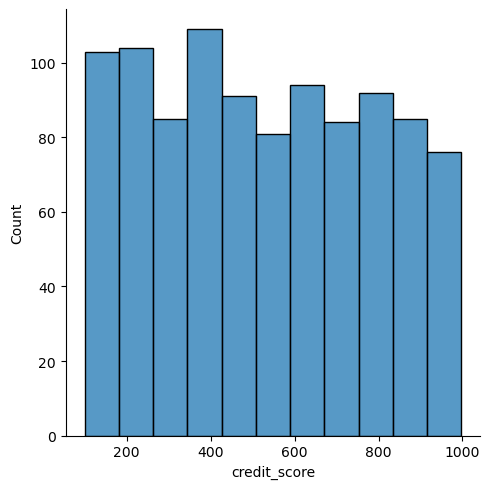

In [4]:
sns.displot(df['credit_score'])

# Shape, info and null values

In [5]:
print("Shape: ", df.shape, "\n")
print(df.info(), "\n")
print("Null values:\n", df.isnull().sum())

Shape:  (1004, 5) 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004 entries, 0 to 1003
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   initial_payment  1004 non-null   int64 
 1   last_payment     1004 non-null   int64 
 2   credit_score     1004 non-null   int64 
 3   sum              1004 non-null   int64 
 4   result           1004 non-null   object
dtypes: int64(4), object(1)
memory usage: 39.3+ KB
None 

Null values:
 initial_payment    0
last_payment       0
credit_score       0
sum                0
result             0
dtype: int64


In [6]:
print(df['result'].value_counts())

result
No     521
yes    483
Name: count, dtype: int64


# Encoding result column to 1 and 0

In [7]:
le = LabelEncoder()
df['result'] = le.fit_transform(df['result'])

In [8]:
df.head()

,initial_payment,last_payment,credit_score,sum,result
0,201,10018,250,13515,1
1,205,10016,395,13660,1
2,257,10129,109,13746,1
3,246,10064,324,13771,1
4,117,10115,496,13822,1


# Correlation

In [9]:
df.corr()

,initial_payment,last_payment,credit_score,sum,result
initial_payment,1.000000,-0.013536,-0.009421,0.050698,-0.048464
last_payment,-0.013536,1.000000,-0.000805,0.213237,-0.805640
credit_score,-0.009421,-0.000805,1.000000,0.068387,-0.076326
sum,0.050698,0.213237,0.068387,1.000000,-0.092830
result,-0.048464,-0.805640,-0.076326,-0.092830,1.000000


<Axes: >

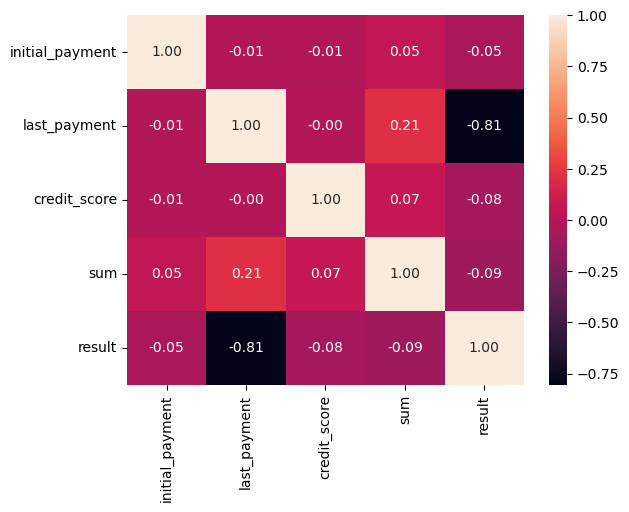

In [10]:
sns.heatmap(df.corr(), annot=True, fmt='.2f')

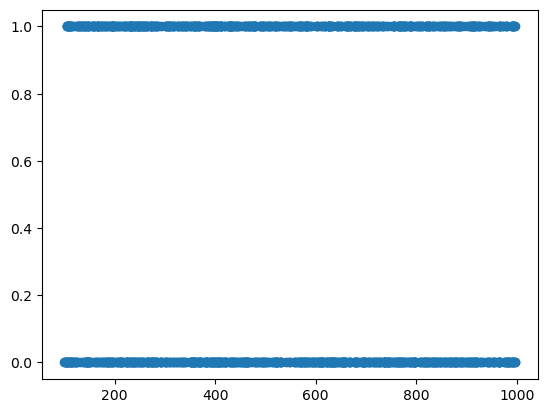

In [11]:
plt.scatter(df['credit_score'], df['result'])

# Split into training and testing sets

In [12]:
X = df.drop(['result'], axis = 1)
y = df.result

In [14]:
X.head()

,initial_payment,last_payment,credit_score,sum
0,201,10018,250,13515
1,205,10016,395,13660
2,257,10129,109,13746
3,246,10064,324,13771
4,117,10115,496,13822


In [15]:
y.head()

0    1
1    1
2    1
3    1
4    1
Name: result, dtype: int64

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=1)

print(f"Training set: {X_train.shape[0]} rows")
print(f"Testing set:  {X_test.shape[0]} rows")

Training set: 753 rows
Testing set:  251 rows


# Feature scaling

In [17]:
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)


# Building and training decision tree model

In [18]:
classifier = DecisionTreeClassifier(criterion='entropy', random_state = 1)
classifier.fit(X_train, y_train)
print("Model trained")
print("Tree depth: ", classifier.get_depth())
print("Number of leaves: ", classifier.get_n_leaves())

Model trained
Tree depth:  4
Number of leaves:  5


# Prediction

In [19]:
y_pred = classifier.predict(X_test)
comp = pd.DataFrame({'Actual':y_test.values[:10], 'Predicted:':y_pred[:10]})
print(comp)

   Actual  Predicted:
0       0           0
1       0           0
2       0           0
3       1           1
4       0           0
5       0           0
6       0           0
7       0           0
8       0           0
9       1           1


# Accuracy

In [20]:
accuracy_score(y_test, y_pred)

1.0

# Classification report

In [21]:
print("Classification report: \n", classification_report(y_test, y_pred))

Classification report: 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       138
           1       1.00      1.00      1.00       113

    accuracy                           1.00       251
   macro avg       1.00      1.00      1.00       251
weighted avg       1.00      1.00      1.00       251



# Confusion matrix

Confusion matrix:
 [[138   0]
 [  0 113]]


<Axes: >

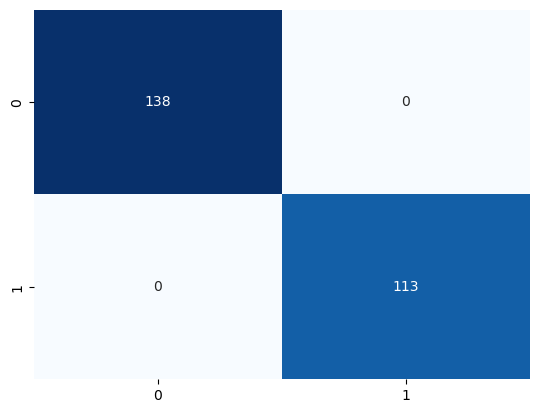

In [22]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:\n", cm)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)

# Importance of feautures

In [23]:
importance = pd.DataFrame({'Feature:': X.columns, 'Importance:':classifier.feature_importances_})
print(importance)

          Feature:  Importance:
0  initial_payment     0.000000
1     last_payment     0.003659
2     credit_score     0.000000
3              sum     0.996341


# Testing new person

In [24]:
new_person = [[200, 12000, 850, 20000]]
new_person = sc.transform(new_person)
prediction = classifier.predict(new_person)
if prediction == 1:
    prediction = "Yes"
else:
    prediction = "No"

print("Predicted result: ", prediction)

Predicted result:  No


C:\Users\benes\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


I found out that credit score has no relevance. Which is weird, because it should be the most important feature in my opininon. All depends on sum column. That is not right. Seems like 2 outliers in this column are throwing the model off. Mean is 17,744 / 75% is 18,608 / but max is 246,789. I decided to drop the outliers.

In [25]:
df2 = df[df['sum'] <= 100000]

In [26]:
df2.describe()

,initial_payment,last_payment,credit_score,sum,result
count,1002.000000,1002.000000,1002.000000,1002.000000,1002.000000
mean,294.455090,12469.067864,528.407186,17323.097804,0.480040
std,115.843906,1440.656433,259.672740,1598.146900,0.499851
min,100.000000,10005.000000,100.000000,13515.000000,0.000000
25%,195.250000,11206.500000,302.250000,16077.750000,0.000000
50%,289.500000,12460.000000,518.000000,17383.000000,0.000000
75%,398.000000,13680.750000,754.500000,18602.000000,1.000000
max,500.000000,14996.000000,997.000000,21786.000000,1.000000


In [27]:
df2.head()

,initial_payment,last_payment,credit_score,sum,result
0,201,10018,250,13515,1
1,205,10016,395,13660,1
2,257,10129,109,13746,1
3,246,10064,324,13771,1
4,117,10115,496,13822,1


Training set: 751 rows
Testing set:  251 rows
Model trained
Tree depth:  3
Number of leaves:  4
   Actual  Predicted:
0       0           0
1       0           0
2       1           1
3       1           1
4       0           0
5       0           0
6       0           0
7       0           0
8       0           0
9       1           1
Classification report: 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       141
           1       1.00      1.00      1.00       110

    accuracy                           1.00       251
   macro avg       1.00      1.00      1.00       251
weighted avg       1.00      1.00      1.00       251

Confusion matrix:
 [[141   0]
 [  0 110]]
          Feature:  Importance:
0  initial_payment     0.000000
1     last_payment     0.005327
2     credit_score     0.000000
3              sum     0.994673



Predicted result for new person:  Yes


C:\Users\benes\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


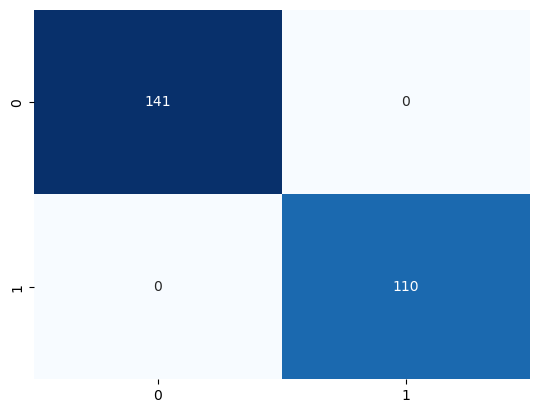

In [28]:
X2 = df2.drop(['result'], axis = 1)
y2 = df2.result
X_train, X_test, y_train, y_test = train_test_split(X2, y2, test_size=0.25, random_state=1)

print(f"Training set: {X_train.shape[0]} rows")
print(f"Testing set:  {X_test.shape[0]} rows")
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

classifier = DecisionTreeClassifier(criterion='entropy', random_state = 1)
classifier.fit(X_train, y_train)
print("Model trained")
print("Tree depth: ", classifier.get_depth())
print("Number of leaves: ", classifier.get_n_leaves())

y_pred = classifier.predict(X_test)
comp = pd.DataFrame({'Actual':y_test.values[:10], 'Predicted:':y_pred[:10]})
print(comp)

accuracy_score(y_test, y_pred)

print("Classification report: \n", classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:\n", cm)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)

importance = pd.DataFrame({'Feature:': X.columns, 'Importance:':classifier.feature_importances_})
print(importance)

new_person = [[200, 12000, 0, 16000]]
new_person = sc.transform(new_person)
prediction = classifier.predict(new_person)
if prediction == 1:
    prediction = "Yes"
else:
    prediction = "No"

print("\n\n\nPredicted result for new person: ", prediction)

Still no relevance for credit score. But model seems to be working well. I feel like I am missing something here but don't know what could it be